<a href="https://colab.research.google.com/github/Alan09G/DS2-Group-Project/blob/main/DS2_Group27_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Part 1: Recycle Image Classification

Retrieving, assessing and normalizing the data

In [ ]:
#pip install kagglehub

In [ ]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("techsash/waste-classification-data")

print("Path to dataset files:", path)
print("Contents:", os.listdir(path))

Using Colab cache for faster access to the 'waste-classification-data' dataset.
Path to dataset files: /kaggle/input/waste-classification-data
Contents: ['DATASET', 'dataset']


In [ ]:
train_dir = os.path.join(path, "DATASET", "TRAIN")
test_dir = os.path.join(path, "DATASET", "TEST")

In [ ]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED =42

#Extract data from path - returns _PrefetchDataset object (A wrapper for tf.data.Dataset)
#training dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

#validation dataset
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

#testing dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

Found 22564 files belonging to 2 classes.
Using 18052 files for training.
Found 22564 files belonging to 2 classes.
Using 4512 files for validation.
Found 2513 files belonging to 2 classes.


In [ ]:
print(train_ds.class_names)
#number of batches
print(train_ds.cardinality().numpy())

['O', 'R']
565


In [ ]:
#normalize the data (convert values from 0-255 to 0-1)
normalize = tf.keras.layers.Rescaling(1./255)

#iterate through each batch, for every x, y pair => normalize x, leave y the same
train_ds = train_ds.map(lambda x, y: (normalize(x),y))
val_ds = val_ds.map(lambda x, y: (normalize(x),y))
test_ds = test_ds.map(lambda x, y: (normalize(x), y))

In [ ]:
#improve dataset loading performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

display 9 images from the first batch of the train data

<class 'tensorflow.python.data.ops.prefetch_op._PrefetchDataset'>
(32, 128, 128, 3)
(32, 1)


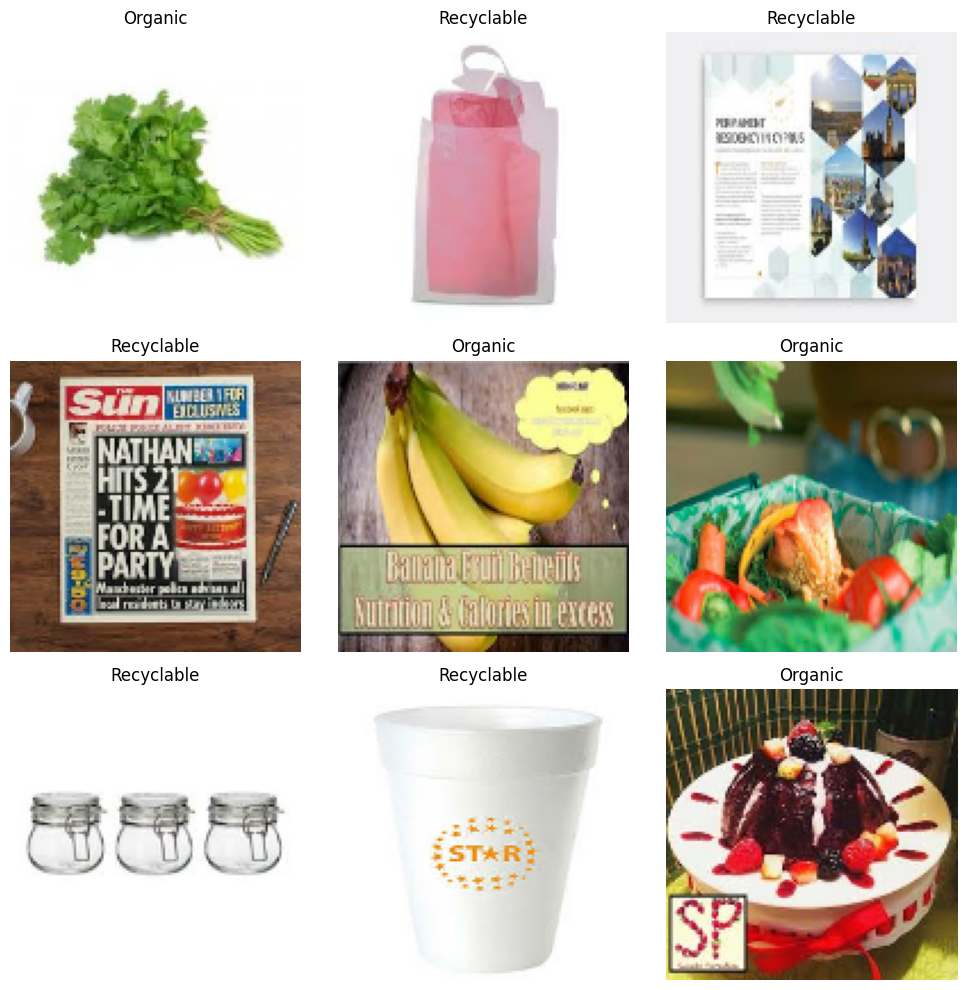

In [ ]:
print(type(train_ds))

class_names = ["Organic", "Recyclable"]

for images, labels in train_ds.take(1):
    print(images.shape)
    print(labels.shape)

    plt.figure(figsize=(10, 10))

    for i in range(9):
        plt.subplot(3,3, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(class_names[int(labels[i].numpy().item())])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

# Random Forest Classifier

images need to be resized to smaller dimensions to decrease the number of features and decrease the computational time to train the model. Images need to be flattened and each pixel is turned into an individual feature.

In [ ]:
#Random Forest
import ydf

#format data for Random Forest Model
def prepare_rf_data(dataset, size=(32, 32)):
  features = []
  labels = []

  for images, batch_labels in dataset:
    #resize images
    images = tf.image.resize(images, size)

    #Flatten each image
    images = tf.reshape(images, [tf.shape(images)[0], -1])

    #convert tensors to numpy arrays
    features.append(images.numpy())
    labels.append(batch_labels.numpy().reshape(-1))

  X = np.concatenate(features)
  y = np.concatenate(labels).astype(int)

  #Convert to named columns for YDF
  data = {
      f"pixel_{i}": X[:, i]
      for i in range(X.shape[1])
  }

  data["class"] = np.where(y == 0, "Organic", "Recyclable")

  return data



# Use ydf's decision tree model

save trained model using google drive to avoid retraining when rerunning the code. Only retrain and analyze(time consuming) when needed.

In [ ]:
from google.colab import drive
from IPython.display import HTML, display
drive.mount('/content/drive')

MODEL_DIR = "/content/drive/MyDrive/DS2_models"
RF_PATH = os.path.join(MODEL_DIR, "rfc_model")
ANALYSIS_PATH = os.path.join(MODEL_DIR, "rfc_analysis.html")
os.makedirs(MODEL_DIR, exist_ok=True)

RETRAIN = False   # set True only when retraining new parameters
RUN_ANALYSIS = False  #analyze is time consuming. Only run when needed

if os.path.exists(RF_PATH) and not RETRAIN:
  #load saved model
  rfc_model = ydf.load_model(RF_PATH)
  print("Loaded saved model from", RF_PATH)
else:
  #preprocess training data and train
  train_rf = prepare_rf_data(train_ds)
  rfc_model = ydf.RandomForestLearner(label="class", task=ydf.Task.CLASSIFICATION, num_trees=100).train(train_rf)
  rfc_model.save(RF_PATH)
  print("Trained and saved model to", RF_PATH)

#preprocess test data
test_rf = prepare_rf_data(test_ds)

predictions = rfc_model.predict(test_rf)
evalutaion = rfc_model.evaluate(test_rf)

#Anlysie the model (e.g. partial dependence plot, variable importance)
if RUN_ANALYSIS:
  analysis = rfc_model.analyze(test_rf)
  analysis

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading model from /content/drive/MyDrive/DS2_models/rfc_model
Loaded saved model from /content/drive/MyDrive/DS2_models/rfc_model


random forest report

In [ ]:
# Random Forest Evaluation Report
print(f"Test accuracy: {evalutaion.accuracy}")
print("Full evaluation report:")
evalutaion


Test accuracy: 0.86549940310386
Full evaluation report:


Label \ Pred,Organic,Recyclable
Organic,1362,39
Recyclable,299,813


# Basic CNN

In [ ]:
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(SEED)

cnn_model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

cnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,392,449 (28.20 MB)

 Trainable params: 7,392,449 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stop]
)

Epoch 1/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 90s 142ms/step - accuracy: 0.8043 - loss: 0.4588 - val_accuracy: 0.8373 - val_loss: 0.3850
Epoch 2/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 18s 32ms/step - accuracy: 0.8393 - loss: 0.3848 - val_accuracy: 0.8329 - val_loss: 0.3870
Epoch 3/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 20s 35ms/step - accuracy: 0.8576 - loss: 0.3472 - val_accuracy: 0.8211 - val_loss: 0.4207
Epoch 4/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 18s 32ms/step - accuracy: 0.8685 - loss: 0.3167 - val_accuracy: 0.8553 - val_loss: 0.3531
Epoch 5/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 18s 32ms/step - accuracy: 0.8899 - loss: 0.2749 - val_accuracy: 0.8500 - val_loss: 0.3553
Epoch 6/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 18s 32ms/step - accuracy: 0.9011 - loss: 0.2492 - val_accuracy: 0.8249 - val_loss: 0.4545
Epoch 7/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - accuracy: 0.9056 - loss: 0.2442 - val_accuracy: 0.8285 - val_loss: 0.4204


In [ ]:
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(test_ds)

print(f"Basic CNN test accuracy: {cnn_test_accuracy:.4f}")
print(f"Basic CNN test loss: {cnn_test_loss:.4f}")

79/79 ━━━━━━━━━━━━━━━━━━━━ 10s 129ms/step - accuracy: 0.8882 - loss: 0.2985
Basic CNN test accuracy: 0.8882
Basic CNN test loss: 0.2985


79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step
              precision    recall  f1-score   support

     Organic     0.8679    0.9429    0.9039      1401
  Recyclable     0.9193    0.8192    0.8664      1112

    accuracy                         0.8882      2513
   macro avg     0.8936    0.8811    0.8851      2513
weighted avg     0.8907    0.8882    0.8873      2513



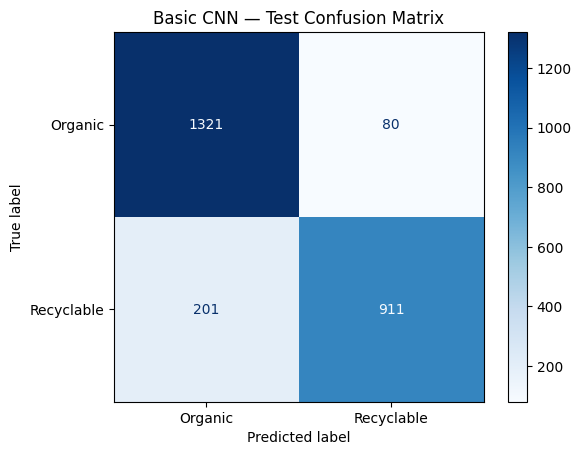

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Test data uses shuffle=False, so labels and predictions stay aligned
y_true = np.concatenate([
    labels.numpy().ravel() for images, labels in test_ds
]).astype(int)

cnn_probabilities = cnn_model.predict(test_ds).ravel()
cnn_predictions = (cnn_probabilities >= 0.5).astype(int)

print(classification_report(
    y_true,
    cnn_predictions,
    labels=[0, 1],
    target_names=["Organic", "Recyclable"],
    digits=4,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    cnn_predictions,
    labels=[0, 1],
    display_labels=["Organic", "Recyclable"],
    cmap="Blues"
)
plt.title("Basic CNN — Test Confusion Matrix")
plt.show()

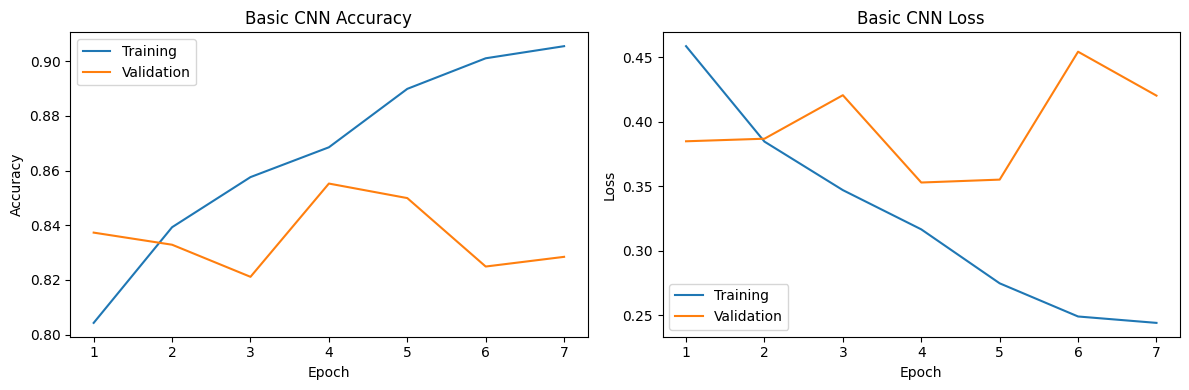

In [ ]:
epochs = range(1, len(cnn_history.history["loss"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, cnn_history.history["accuracy"], label="Training")
plt.plot(epochs, cnn_history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Basic CNN Accuracy")
plt.xticks(epochs)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, cnn_history.history["loss"], label="Training")
plt.plot(epochs, cnn_history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Basic CNN Loss")
plt.xticks(epochs)
plt.legend()

plt.tight_layout()
plt.show()

# MobileNetV2

In [ ]:
tf.keras.utils.set_random_seed(SEED)

mobile_base = tf.keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)

# Keep the pretrained weights fixed
mobile_base.trainable = False

inputs = layers.Input(shape=(128, 128, 3))

# Our datasets are already scaled to [0, 1].
# MobileNetV2 needs inputs scaled to [-1, 1].
x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)

x = mobile_base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

mobile_model = models.Model(inputs, outputs)

mobile_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

mobile_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
mobile_early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

mobile_history = mobile_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[mobile_early_stop]
)

Epoch 1/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 38s 46ms/step - accuracy: 0.8983 - loss: 0.2547 - val_accuracy: 0.9269 - val_loss: 0.1904
Epoch 2/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 20s 35ms/step - accuracy: 0.9272 - loss: 0.1939 - val_accuracy: 0.9315 - val_loss: 0.1774
Epoch 3/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - accuracy: 0.9323 - loss: 0.1821 - val_accuracy: 0.9328 - val_loss: 0.1736
Epoch 4/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - accuracy: 0.9342 - loss: 0.1778 - val_accuracy: 0.9353 - val_loss: 0.1726
Epoch 5/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - accuracy: 0.9360 - loss: 0.1745 - val_accuracy: 0.9337 - val_loss: 0.1695
Epoch 6/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - accuracy: 0.9351 - loss: 0.1737 - val_accuracy: 0.9340 - val_loss: 0.1703
Epoch 7/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - accuracy: 0.9358 - loss: 0.1719 - val_accuracy: 0.9353 - val_loss: 0.1732
Epoch 8/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 21s 34ms/step - accuracy: 0.9364 - loss: 0.1684 - 

In [ ]:
mobile_test_loss, mobile_test_accuracy = mobile_model.evaluate(test_ds)

print(f"MobileNetV2 test accuracy: {mobile_test_accuracy:.4f}")
print(f"MobileNetV2 test loss: {mobile_test_loss:.4f}")

79/79 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - accuracy: 0.9021 - loss: 0.2372
MobileNetV2 test accuracy: 0.9021
MobileNetV2 test loss: 0.2372


79/79 ━━━━━━━━━━━━━━━━━━━━ 10s 67ms/step
              precision    recall  f1-score   support

     Organic     0.8671    0.9736    0.9173      1401
  Recyclable     0.9606    0.8121    0.8801      1112

    accuracy                         0.9021      2513
   macro avg     0.9139    0.8928    0.8987      2513
weighted avg     0.9085    0.9021    0.9008      2513



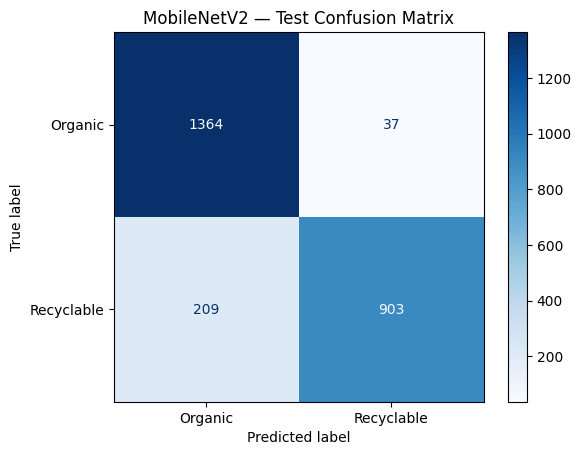

In [ ]:
mobile_probabilities = mobile_model.predict(test_ds).ravel()
mobile_predictions = (mobile_probabilities >= 0.5).astype(int)

print(classification_report(
    y_true,
    mobile_predictions,
    labels=[0, 1],
    target_names=["Organic", "Recyclable"],
    digits=4,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    mobile_predictions,
    labels=[0, 1],
    display_labels=["Organic", "Recyclable"],
    cmap="Blues"
)
plt.title("MobileNetV2 — Test Confusion Matrix")
plt.show()

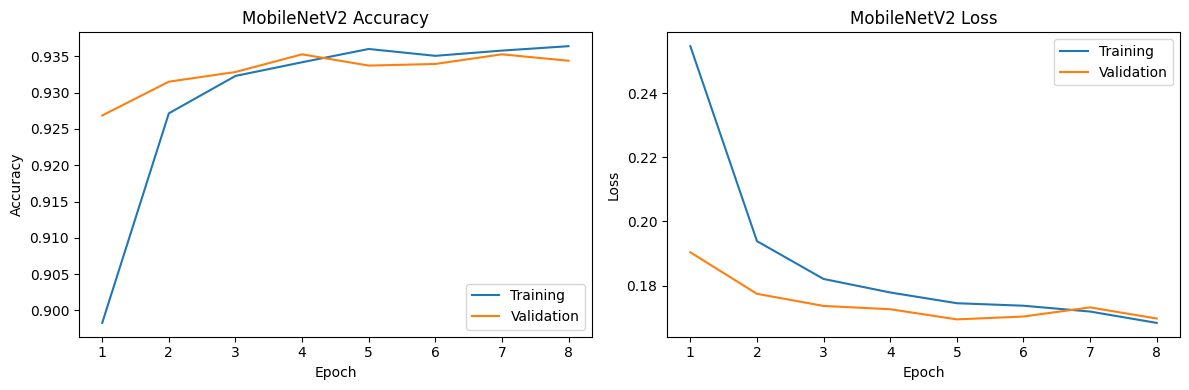

In [ ]:
epochs = range(1, len(mobile_history.history["loss"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, mobile_history.history["accuracy"], label="Training")
plt.plot(epochs, mobile_history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV2 Accuracy")
plt.xticks(epochs)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, mobile_history.history["loss"], label="Training")
plt.plot(epochs, mobile_history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MobileNetV2 Loss")
plt.xticks(epochs)
plt.legend()

plt.tight_layout()
plt.show()